In [176]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline

COPYING torch more closely

In [ ]:
import torch
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True # not Constants
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('do/dx2', x2.grad.item())
print('do/dw2', w2.grad.item())
print('do/x1', x1.grad.item())
print('do/w1', w1.grad.item())

Graphing helper func

In [100]:
from graphviz import Digraph

def trace(root):
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._children:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      dot.node(name = uid + n._op, label = n._op)
      dot.edge(uid + n._op, uid)
  for n1, n2 in edges:
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)
  return dot

In [198]:
class Value:
	def __init__(self, data, _children=(), _op="", label=""):
		self.data = data
		self._children = set(_children)
		self._op = _op
		self.label = label
		self.grad = 0

		self._backprop = lambda: None
	
	def __repr__(self):
		return f"Value({self.data})"
	
	def _clean_value(self, other):
		# inputs: int, float, Value
		# output: Value
		if isinstance(other, int) or isinstance(other, float):
			return Value(other)
		assert type(self) == type(other), "not a tensor"
		return other

	def __add__(self, other):
		v = self._clean_value(other)
		out = Value(self.data + v.data, (self, v), _op="+")

		def _backwards():
			self.grad += out.grad * 1.0
			v.grad += out.grad * 1.0
		
		out._backprop = _backwards
		return out
	
	def __radd__(self, other): # other + self
		return self + other
	
	def __mul__(self, other):
		v = self._clean_value(other)
		out = Value(self.data * v.data, (self, v), _op="*")

		def _backwards():
			self.grad += out.grad * v.data
			v.grad += out.grad * self.data
		
		out._backprop = _backwards
		return out
	
	def __rmul__(self, other):
		return self * other
	
	def __truediv__(self, other):
		return self * other**-1
	
	def __pow__(self, other):
		x = self.data
		v = self._clean_value(other)
		k = v.data
		out = Value(x**k, (self,v), _op="**")
		def _backwards():
			self.grad += out.grad * k * (x**(k-1))		# self**other
			v.grad += out.grad * out.data * np.log(x)
		out._backprop = _backwards
		return out
	
	def __neg__(self):
		return self * -1
	
	def __sub__(self, other):
		return self + (-other)

	def __rsub__(self, other):
		return other + (-self)

	def backward(self):
		topo = []
		visited = set()
		def build_topo(v):
			if v not in visited:
				visited.add(v)
				for child in v._children:
					build_topo(child)
				topo.append(v)
		build_topo(self)

		self.grad = 1.0
		for node in reversed(topo):
			node._backprop()
	

	### OTHER ###

	def exp(self):
		x = self.data
		v = np.exp(x)
		out = Value(v, (self,), _op="exp")
		def _backwards():
			self.grad += out.grad * v
		out._backprop = _backwards
		return out
	
	def tanh(self):
		x = self.data
		t = np.tanh(x)
		out = Value(t, (self,), _op="tanh")
		def _backwards():
			self.grad += out.grad * (1 - t**2)
		out._backprop = _backwards

		return out
	
	def relu(self):
		x = self.data
		v = np.max(x, 0) 
		out = Value(v, (self,), _op="relu")
		def _backwards():
			self.grad = out.grad * (1 if x > 0 else 0)
		out._backprop = _backwards
		return out

	def sigmoid(self):
		x = self.data
		v = 1 / (1 + np.exp(-x))
		out = Value(v, (self,), _op="sigmoid")
		def _backwards():
			self.grad = out.grad * v * (1-v)
		out._backprop = _backwards
		return out

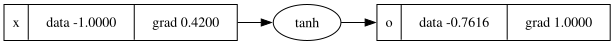

In [174]:
x = Value(-1, label="x")
o = x.tanh(); o.label="o"
o.backward()
draw_dot(o)

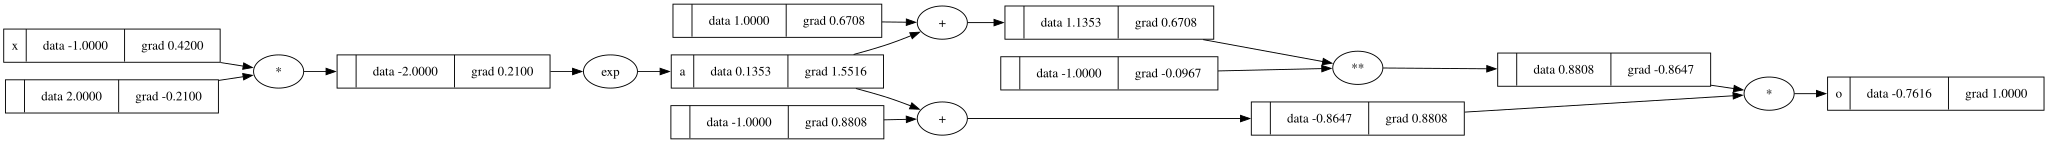

In [175]:
# EQUIVALENT but in longer form
x = Value(-1, label="x")
e = (2*x).exp(); e.label="a"
o = (e - 1) / (e + 1); o.label="o"
o.backward()
draw_dot(o)


In [231]:
class Neuron:
	def __init__(self, n, nout_index):
		self.w = [Value(random.uniform(-1, 1), label=f"w_{i},{nout_index}") for i in range(n)]
		self.b = Value(random.uniform(-1, 1), label=f"b_{nout_index}")

	def __call__(self, x):
		# tanh(w*x + b)
		n = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
		out = n.tanh()
		return out

	def parameters(self):
		return self.w + [self.b]

class Layer:
	def __init__(self, nin, nout):
		self.neurons = [Neuron(nin, nout_index=j) for j in range(nout)]

	def __call__(self, x):
		outs = [n(x) for n in self.neurons]
		return outs[0] if len(outs) == 1 else outs
	
	def parameters(self):
		return [v for n in self.neurons for v in n.parameters()]


class MLP:
	def __init__(self, ndims):
		self.ndims = ndims
		self.layers = [Layer(ndims[i], ndims[i+1]) for i in range(len(ndims) - 1)]
	
	def __call__(self, x):
		for layer in self.layers:
			x = layer(x)
		return x
	
	def parameters(self):
		return [v for layer in self.layers for v in layer.parameters()]

class Optimizer:
	def __init__(self, params, lr = 1e-3):
		self.params = params
		self.lr = lr
	
	def zero_grad(self):
		for val in self.params:
			val.grad = 0.0

	def step(self):
		# gradient descent
		for val in self.params:
			val.data -= self.lr * val.grad

In [232]:
ns = [3, 2]
model = MLP(ns)
model.parameters()

[Value(0.39683138041854105),
 Value(-0.9078842872351518),
 Value(-0.7680792503484528),
 Value(-0.7871538187181908),
 Value(0.7396519530580854),
 Value(0.7120014911419192),
 Value(0.3289561558402798),
 Value(-0.7643106582402373)]

In [233]:
def criterion(output, target):
	assert len(output) == len(target)
	return sum([(pred-y)**2 for pred, y in zip(output, target)]) / len(target)

In [238]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]

model = MLP([3, 4, 3, 2, 1])
optimizer = Optimizer(model.parameters(), lr=0.5)

epochs = 20
loss_curve = []
for i in range(epochs):
	preds = []
	for x in xs:
		output = model(x)
		preds.append(output)

	optimizer.zero_grad()

	loss = criterion(preds, ys)
	loss.backward()
	optimizer.step()

	loss_curve.append(loss.data)
	print(loss.data)

1.3118637014321726
0.9823084691056527
0.9742487658677841
1.545707385410274
0.6984359070928781
0.32035226945775674
0.08409452443913856
0.03754355031136119
0.028904453857087037
0.023750631078568677
0.020184380535760653
0.017541922992842292
0.015499031033316941
0.013871051731991692
0.012543157697487364
0.011439629261305966
0.010508332494510629
0.00971213877224342
0.009023867817315994
0.008423158227266796


/tmp/ipykernel_2403545/862465623.py:60: RuntimeWarning: invalid value encountered in log
  v.grad += out.grad * out.data * np.log(x)


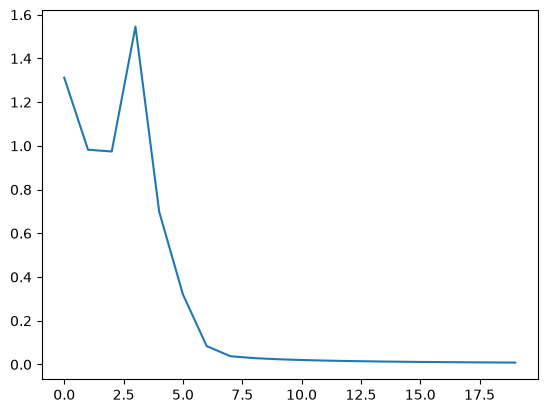

In [239]:
plt.plot(loss_curve)

In [237]:
preds

[Value(0.9399962959145808),
 Value(-0.9429516387661444),
 Value(-0.9193732938355885),
 Value(0.9147379478481792)]

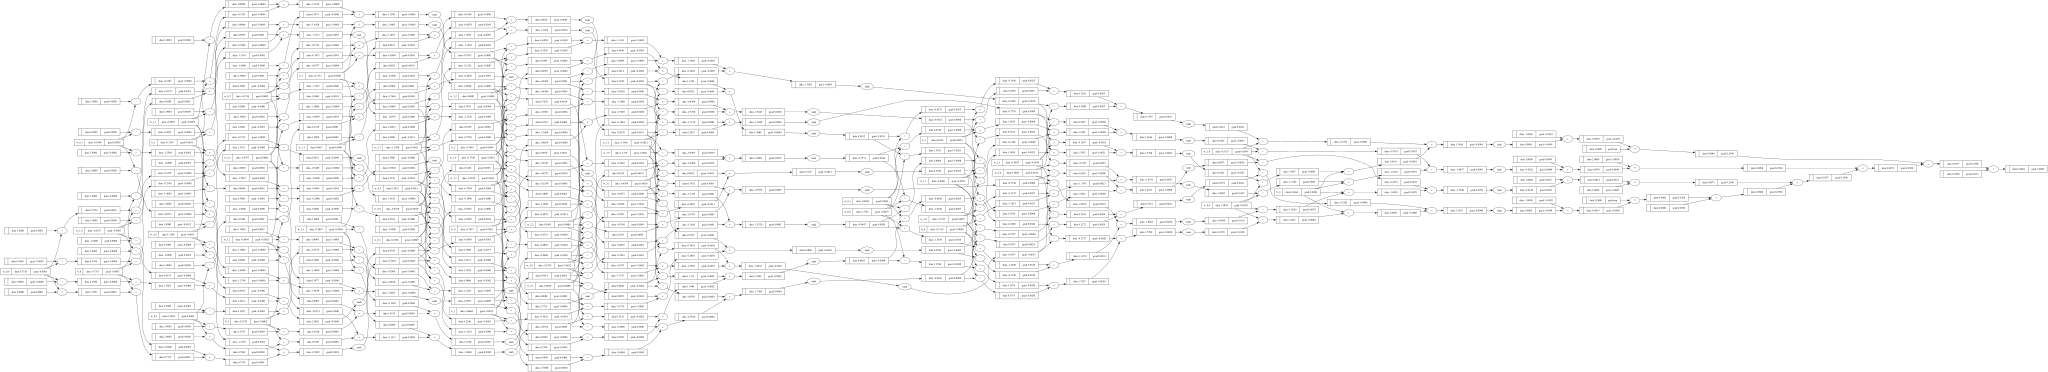

In [240]:
draw_dot(loss)